# VST IMS — Training Debug Notebook
Run each cell sequentially to find exactly where training fails.

In [38]:
import sys
import os
sys.path.insert(0, os.path.join(os.getcwd(), 'backend'))
print('Python:', sys.version)
print('Working dir:', os.getcwd())

Python: 3.12.7 | packaged by Anaconda, Inc. | (main, Oct  4 2024, 13:17:27) [MSC v.1929 64 bit (AMD64)]
Working dir: D:\VST_PROJECTS\IMS_VST\V2_vst


## Step 1: Check Dependencies

In [40]:
deps = {
    'xgboost': 'xgboost',
    'lightgbm': 'lightgbm',
    'statsmodels': 'statsmodels',
    'prophet': 'prophet',
    'pandas': 'pandas',
    'numpy': 'numpy',
    'sklearn': 'sklearn',
    'joblib': 'joblib',
    'sqlalchemy': 'sqlalchemy',
}
for name, pkg in deps.items():
    try:
        mod = __import__(pkg)
        ver = getattr(mod, '__version__', 'ok')
        print(f'  [OK] {name}: {ver}')
    except ImportError:
        print(f'  [MISSING] {name} — pip install {pkg}')

  [OK] xgboost: 3.4.0
  [OK] lightgbm: 4.7.0
  [OK] statsmodels: 0.14.2
  [OK] prophet: 1.3.0
  [OK] pandas: 2.2.2
  [OK] numpy: 1.26.4
  [OK] sklearn: 1.5.1
  [OK] joblib: 1.4.2
  [OK] sqlalchemy: 2.0.34


## Step 2: Load Sales Data (CSV fallback)

In [42]:
import pandas as pd
from pathlib import Path

csv_path = Path('data/fact_sales.csv')
print(f'CSV exists: {csv_path.exists()}')

if csv_path.exists():
    sales = pd.read_csv(csv_path, parse_dates=['Date'])
    print(f'Sales shape: {sales.shape}')
    print(f'Columns: {list(sales.columns)}')
    print(f'SKU count: {sales["SKU_ID"].nunique()}')
    print(f'Date range: {sales["Date"].min()} to {sales["Date"].max()}')
    print(f'Weeks of data: {sales["Date"].nunique()}')
    print(f'\nFirst 3 rows:')
    display(sales.head(3))
else:
    print('ERROR: fact_sales.csv not found!')
    print('Files in data/:', list(Path('data').glob('*')))

CSV exists: True
Sales shape: (41800, 5)
Columns: ['Date', 'SKU_ID', 'Units_Sold', 'Fulfillment_Region', 'Stockout_Flag']
SKU count: 200
Date range: 2022-01-03 00:00:00 to 2025-12-29 00:00:00
Weeks of data: 209

First 3 rows:


,Date,SKU_ID,Units_Sold,Fulfillment_Region,Stockout_Flag
0,2022-01-03,SP-FIL-0001,31,Export,0
1,2022-01-10,SP-FIL-0001,39,South India,1
2,2022-01-17,SP-FIL-0001,26,South India,0


## Step 3: Run prepare_dataset()

In [44]:
from app.forecasting.data_pipeline import prepare_dataset

try:
    dataset = prepare_dataset(test_weeks=12)
    print(f'Train rows: {dataset["train_rows"]}')
    print(f'Test rows:  {dataset["test_rows"]}')
    print(f'Features:   {len(dataset["feature_cols"])}')
    print(f'SKUs:       {len(dataset["sku_ids"])}')
    print(f'Split date: {dataset["split_date"]}')
    print(f'\nTrain target stats:')
    print(dataset['train']['target'].describe())
except Exception as e:
    print(f'FAILED: {e}')
    import traceback; traceback.print_exc()

Train rows: 38600
Test rows:  2400
Features:   38
SKUs:       200
Split date: 2025-10-13 00:00:00

Train target stats:
count    38600.000000
mean        24.801166
std         21.203402
min          0.000000
25%          7.000000
50%         19.000000
75%         38.000000
max        132.000000
Name: target, dtype: float64


## Step 4: Test Each Model Individually

In [46]:
import numpy as np
import pandas as pd
from app.forecasting.data_pipeline import prepare_dataset, prepare_timeseries_for_sku, get_feature_columns

dataset = prepare_dataset(test_weeks=12)
train_df = dataset['train']
test_df = dataset['test']
feature_cols = dataset['feature_cols']

X_train = pd.DataFrame(train_df[feature_cols].values, columns=feature_cols)
y_train = pd.Series(train_df['target'].values)
X_test = pd.DataFrame(test_df[feature_cols].values, columns=feature_cols)
y_test = test_df['target'].values

print(f'X_train: {X_train.shape}, y_train: {y_train.shape}')
print(f'X_test:  {X_test.shape},  y_test:  {y_test.shape}')
print(f'Any NaN in X_train: {X_train.isna().any().any()}')
print(f'Any Inf in X_train: {np.isinf(X_train.values).any()}')
print(f'y_train range: [{y_train.min()}, {y_train.max()}]')

X_train: (38600, 38), y_train: (38600,)
X_test:  (2400, 38),  y_test:  (2400,)
Any NaN in X_train: False
Any Inf in X_train: False
y_train range: [0, 132]


In [47]:
# 4a: XGBoost
print('--- XGBoost ---')
try:
    from xgboost import XGBRegressor
    model = XGBRegressor(n_estimators=100, max_depth=6, learning_rate=0.05, random_state=42, verbosity=0, tree_method='hist')
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    mae = float(np.mean(np.abs(y_test - preds)))
    print(f'  [OK] MAE: {mae:.2f}, Pred range: [{preds.min():.1f}, {preds.max():.1f}]')
except Exception as e:
    print(f'  [FAIL] {e}')
    import traceback; traceback.print_exc()

--- XGBoost ---
  [OK] MAE: 1.24, Pred range: [0.5, 115.0]


In [48]:
# 4b: LightGBM
print('--- LightGBM ---')
try:
    from lightgbm import LGBMRegressor
    model = LGBMRegressor(n_estimators=100, max_depth=7, learning_rate=0.05, random_state=42, verbose=-1)
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    mae = float(np.mean(np.abs(y_test - preds)))
    print(f'  [OK] MAE: {mae:.2f}, Pred range: [{preds.min():.1f}, {preds.max():.1f}]')
except Exception as e:
    print(f'  [FAIL] {e}')
    import traceback; traceback.print_exc()

--- LightGBM ---
  [OK] MAE: 1.47, Pred range: [1.2, 114.8]


In [49]:
# 4c: ARIMA
print('--- ARIMA ---')
try:
    rep_sku = dataset['sku_ids'][0]
    print(f'  Representative SKU: {rep_sku}')
    ts_data = prepare_timeseries_for_sku(rep_sku)
    ts_values = ts_data['Units_Sold']
    print(f'  TS length: {len(ts_values)}')
    
    ts_train = ts_values.iloc[:-12] if len(ts_values) > 12 else ts_values
    print(f'  TS train length: {len(ts_train)}')
    
    from statsmodels.tsa.arima.model import ARIMA
    model = ARIMA(ts_train.values.astype(float), order=(2, 1, 2))
    fitted = model.fit()
    forecast = fitted.forecast(steps=12)
    print(f'  [OK] Forecast: {forecast[:3]}...')
except Exception as e:
    print(f'  [FAIL] {e}')
    import traceback; traceback.print_exc()

--- ARIMA ---
  Representative SKU: EN-DIE-0002
  TS length: 209
  TS train length: 197
  [OK] Forecast: [4.95638758 5.22035528 5.00025713]...


In [50]:
# 4d: SARIMA
print('--- SARIMA ---')
try:
    from statsmodels.tsa.statespace.sarimax import SARIMAX
    
    seasonal_order = (1, 1, 1, 52)
    if len(ts_train) < seasonal_order[3] * 2:
        seasonal_order = (1, 0, 1, 13)
        print(f'  Using reduced seasonal: {seasonal_order}')
    
    model = SARIMAX(
        ts_train.values.astype(float),
        order=(1, 1, 1),
        seasonal_order=seasonal_order,
        enforce_stationarity=False,
        enforce_invertibility=False,
    )
    fitted = model.fit(disp=False, maxiter=100)
    forecast = fitted.forecast(steps=12)
    print(f'  [OK] Forecast: {forecast[:3]}...')
except Exception as e:
    print(f'  [FAIL] {e}')
    import traceback; traceback.print_exc()

--- SARIMA ---
  [OK] Forecast: [6.27245661 5.31408036 6.24335433]...


In [51]:
# 4e: Prophet
print('--- Prophet ---')
try:
    from prophet import Prophet
    
    prophet_df = pd.DataFrame({
        'ds': ts_train.index.to_series().reset_index(drop=True),
        'y': ts_train.values.flatten(),
    })
    print(f'  Prophet df shape: {prophet_df.shape}')
    
    m = Prophet(
        changepoint_prior_scale=0.05,
        seasonality_prior_scale=10,
        yearly_seasonality=True,
        weekly_seasonality=False,
    )
    m.add_seasonality(name='monsoon', period=26, fourier_order=5)
    m.fit(prophet_df)
    future = m.make_future_dataframe(periods=12, freq='W-MON')
    forecast = m.predict(future)
    print(f'  [OK] Forecast tail: {forecast["yhat"].tail(3).values}')
except Exception as e:
    print(f'  [FAIL] {e}')
    import traceback; traceback.print_exc()

21:38:18 - cmdstanpy - INFO - Chain [1] start processing
21:38:18 - cmdstanpy - INFO - Chain [1] done processing


--- Prophet ---
  Prophet df shape: (197, 2)
  [OK] Forecast tail: [4.69815574 5.44903283 4.20498425]


In [52]:
# 4f: Holt-Winters
print('--- Holt-Winters ---')
try:
    from statsmodels.tsa.holtwinters import ExponentialSmoothing
    
    values = ts_train.values.astype(float).flatten()
    sp = 52
    if len(values) < sp * 2:
        sp = min(13, len(values) // 2)
        if sp < 2:
            sp = None
    print(f'  Seasonal periods: {sp}')
    
    if sp and sp >= 2:
        model = ExponentialSmoothing(values, trend='add', seasonal='add', seasonal_periods=sp)
    else:
        model = ExponentialSmoothing(values, trend='add', seasonal=None)
    
    fitted = model.fit(optimized=True)
    forecast = fitted.forecast(12)
    print(f'  [OK] Forecast: {forecast[:3]}')
except Exception as e:
    print(f'  [FAIL] {e}')
    import traceback; traceback.print_exc()

--- Holt-Winters ---
  Seasonal periods: 52
  [OK] Forecast: [5.75477301 5.08810539 6.08808323]


## Step 5: Run Full Ensemble Training

In [54]:
from app.forecasting.ensemble import AdaptiveEnsemble

ensemble = AdaptiveEnsemble()
results = ensemble.train_all_models(test_weeks=12)

import json
print(json.dumps(results, indent=2, default=str)[:3000])

21:38:25 - cmdstanpy - INFO - Chain [1] start processing
21:38:25 - cmdstanpy - INFO - Chain [1] done processing


{
  "models": {
    "xgboost": {
      "status": "trained",
      "train_result": {
        "train_mae": 1.2153257249966578,
        "n_features": 38
      },
      "test_metrics": {
        "mae": 0.9536,
        "mape": 6.03,
        "rmse": 1.5845,
        "smape": 6.65,
        "bias": 0.22,
        "n_samples": 2400
      }
    },
    "lightgbm": {
      "status": "trained",
      "train_result": {
        "train_mae": 1.1178247656818583,
        "n_features": 38
      },
      "test_metrics": {
        "mae": 0.8301,
        "mape": 5.23,
        "rmse": 1.4229,
        "smape": 5.89,
        "bias": 0.16,
        "n_samples": 2400
      }
    },
    "arima": {
      "status": "trained",
      "train_result": {
        "train_mae": 1.0223687937817703,
        "aic": 664.5402798171715
      },
      "test_metrics": {
        "mae": 1.0203,
        "mape": 16.89,
        "rmse": 1.1911,
        "smape": 18.62,
        "bias": -15.6,
        "n_samples": 12
      }
    },
    "sarim

## Step 6: Check Individual Model Results

In [56]:
if 'models' in results:
    for name, res in results['models'].items():
        status = res.get('status', 'unknown')
        if status == 'trained':
            mape = res.get('test_metrics', {}).get('mape', 'N/A')
            print(f'  [TRAINED] {name}: MAPE={mape}%')
        else:
            err = res.get('error', 'unknown')
            print(f'  [FAILED]  {name}: {err[:200]}')
else:
    print('No models key in results. Full response:')
    print(results)

  [TRAINED] xgboost: MAPE=6.03%
  [TRAINED] lightgbm: MAPE=5.23%
  [TRAINED] arima: MAPE=16.89%
  [TRAINED] sarima: MAPE=11.85%
  [TRAINED] prophet: MAPE=7.93%
  [TRAINED] holt_winters: MAPE=12.14%


## Step 7: Model Performance Comparison Chart

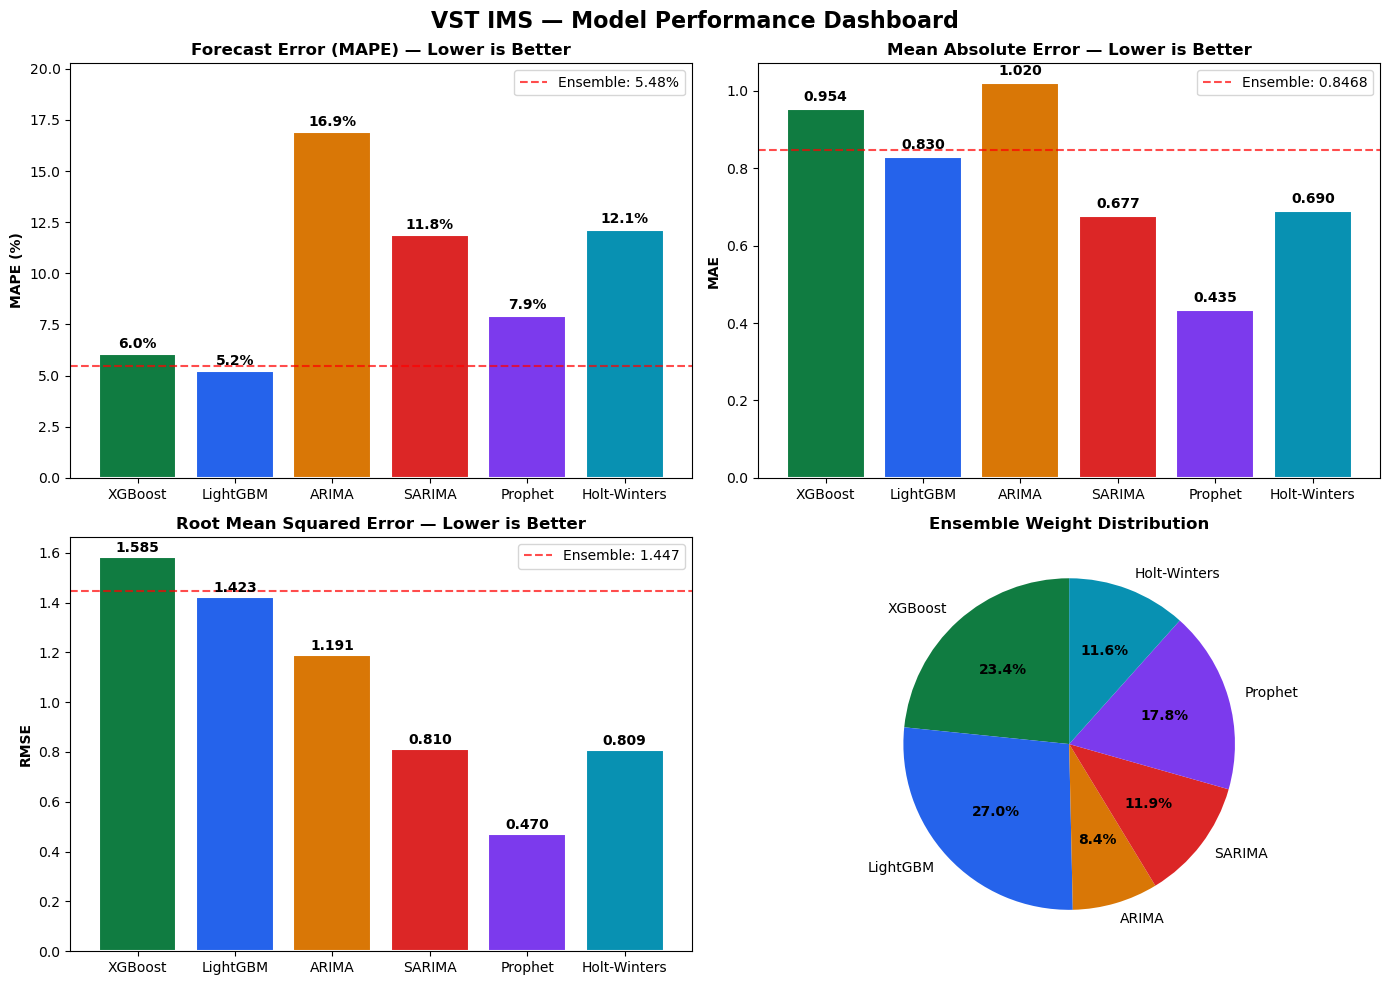

Chart saved to model_comparison.png


In [58]:
import matplotlib.pyplot as plt
import numpy as np

model_names = ['XGBoost', 'LightGBM', 'ARIMA', 'SARIMA', 'Prophet', 'Holt-Winters']
model_keys = ['xgboost', 'lightgbm', 'arima', 'sarima', 'prophet', 'holt_winters']
colors = ['#107c41', '#2563eb', '#d97706', '#dc2626', '#7c3aed', '#0891b2']

mapes = [results['models'][k]['test_metrics']['mape'] for k in model_keys]
maes = [results['models'][k]['test_metrics']['mae'] for k in model_keys]
rmses = [results['models'][k]['test_metrics']['rmse'] for k in model_keys]
weights = [results['weights'][k] * 100 for k in model_keys]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('VST IMS — Model Performance Dashboard', fontsize=16, fontweight='bold')

# MAPE comparison
ax = axes[0, 0]
bars = ax.bar(model_names, mapes, color=colors, edgecolor='white', linewidth=1.5)
ax.set_ylabel('MAPE (%)', fontweight='bold')
ax.set_title('Forecast Error (MAPE) — Lower is Better', fontweight='bold')
for bar, v in zip(bars, mapes):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3, f'{v:.1f}%', ha='center', fontweight='bold')
ax.axhline(y=results['ensemble']['mape'], color='red', linestyle='--', alpha=0.7, label=f'Ensemble: {results["ensemble"]["mape"]}%')
ax.legend()
ax.set_ylim(0, max(mapes) * 1.2)

# MAE comparison
ax = axes[0, 1]
bars = ax.bar(model_names, maes, color=colors, edgecolor='white', linewidth=1.5)
ax.set_ylabel('MAE', fontweight='bold')
ax.set_title('Mean Absolute Error — Lower is Better', fontweight='bold')
for bar, v in zip(bars, maes):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02, f'{v:.3f}', ha='center', fontweight='bold')
ax.axhline(y=results['ensemble']['mae'], color='red', linestyle='--', alpha=0.7, label=f'Ensemble: {results["ensemble"]["mae"]}')
ax.legend()

# RMSE comparison
ax = axes[1, 0]
bars = ax.bar(model_names, rmses, color=colors, edgecolor='white', linewidth=1.5)
ax.set_ylabel('RMSE', fontweight='bold')
ax.set_title('Root Mean Squared Error — Lower is Better', fontweight='bold')
for bar, v in zip(bars, rmses):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02, f'{v:.3f}', ha='center', fontweight='bold')
ax.axhline(y=results['ensemble']['rmse'], color='red', linestyle='--', alpha=0.7, label=f'Ensemble: {results["ensemble"]["rmse"]}')
ax.legend()

# Ensemble weights
ax = axes[1, 1]
wedges, texts, autotexts = ax.pie(weights, labels=model_names, colors=colors, autopct='%1.1f%%', startangle=90)
ax.set_title('Ensemble Weight Distribution', fontweight='bold')
for t in autotexts:
    t.set_fontweight('bold')

plt.tight_layout()
plt.savefig('model_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print('Chart saved to model_comparison.png')

## Step 8: Actual vs Predicted — ARIMA/SARIMA Deep Dive

21:38:29 - cmdstanpy - INFO - Chain [1] start processing
21:38:29 - cmdstanpy - INFO - Chain [1] done processing


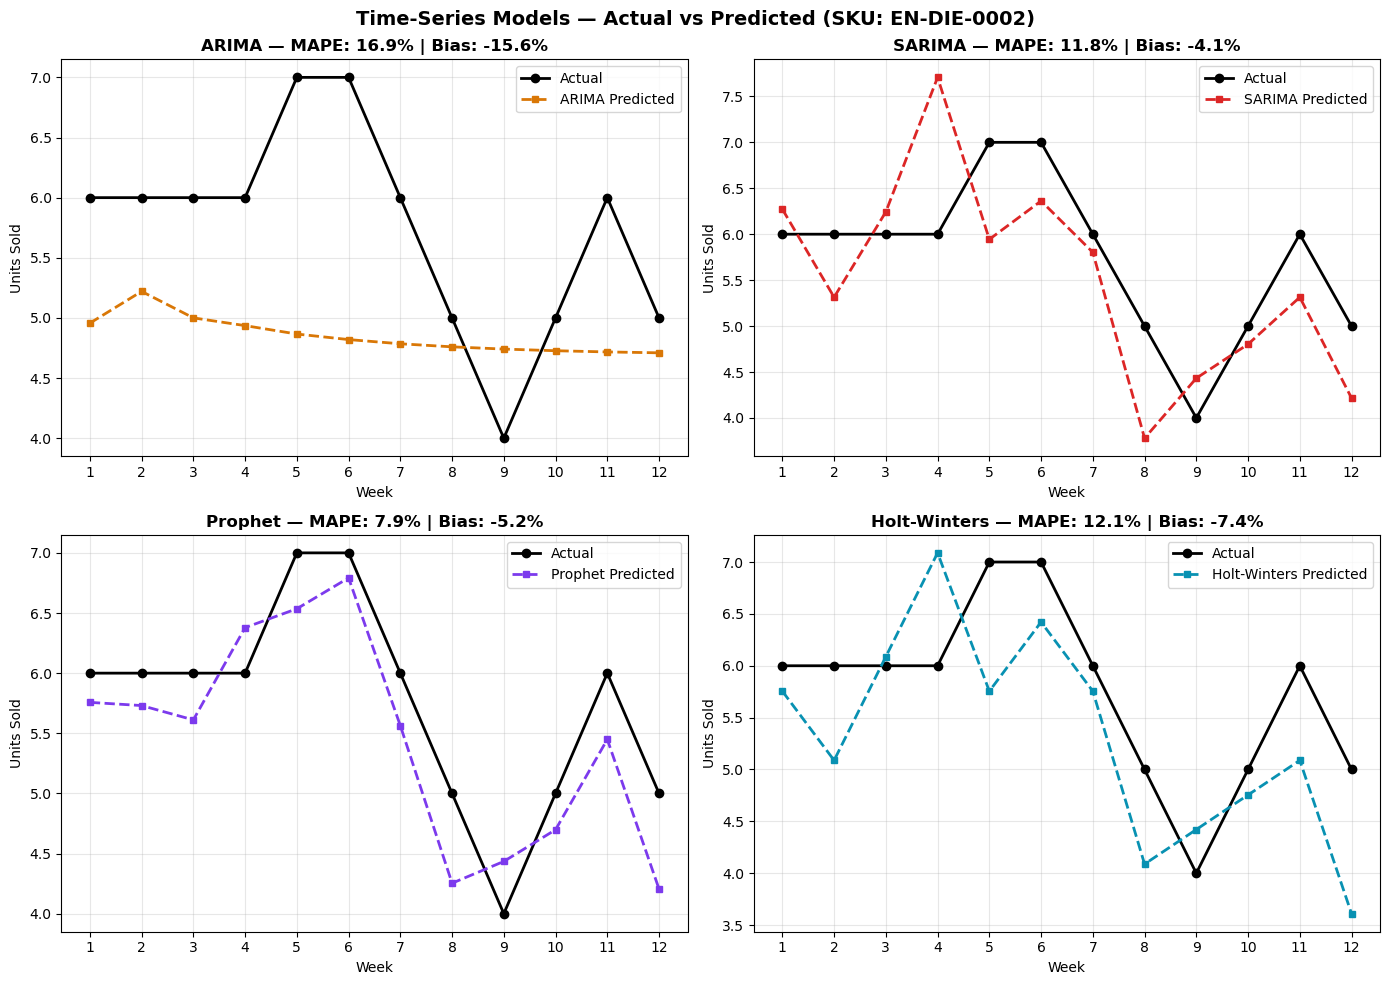

Chart saved to timeseries_models.png


In [60]:
from app.forecasting.data_pipeline import prepare_timeseries_for_sku

rep_sku = dataset['sku_ids'][0]
ts_data = prepare_timeseries_for_sku(rep_sku)
ts_values = ts_data['Units_Sold']
ts_train = ts_values.iloc[:-12]
ts_actual = ts_values.iloc[-12:].values

# Get predictions from each TS model
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from prophet import Prophet
from statsmodels.tsa.holtwinters import ExponentialSmoothing
import pandas as pd

ts_preds = {}

# ARIMA
try:
    m = ARIMA(ts_train.values.astype(float), order=(2,1,2)).fit()
    ts_preds['ARIMA'] = m.forecast(steps=12)
except Exception as e:
    print(f'ARIMA error: {e}')

# SARIMA
try:
    so = (1,0,1,13) if len(ts_train) < 104 else (1,1,1,52)
    m = SARIMAX(ts_train.values.astype(float), order=(1,1,1), seasonal_order=so,
                enforce_stationarity=False, enforce_invertibility=False).fit(disp=False, maxiter=100)
    ts_preds['SARIMA'] = m.forecast(steps=12)
except Exception as e:
    print(f'SARIMA error: {e}')

# Prophet
try:
    pdf = pd.DataFrame({'ds': ts_train.index.to_series().reset_index(drop=True), 'y': ts_train.values.flatten()})
    m = Prophet(changepoint_prior_scale=0.05, yearly_seasonality=True, weekly_seasonality=False)
    m.add_seasonality(name='monsoon', period=26, fourier_order=5)
    m.fit(pdf)
    future = m.make_future_dataframe(periods=12, freq='W-MON')
    fc = m.predict(future)
    ts_preds['Prophet'] = fc['yhat'].values[-12:]
except Exception as e:
    print(f'Prophet error: {e}')

# Holt-Winters
try:
    vals = ts_train.values.astype(float).flatten()
    sp = min(13, len(vals)//2) if len(vals) < 104 else 52
    m = ExponentialSmoothing(vals, trend='add', seasonal='add' if sp>=2 else None, seasonal_periods=sp if sp>=2 else None)
    fitted = m.fit(optimized=True)
    ts_preds['Holt-Winters'] = fitted.forecast(12)
except Exception as e:
    print(f'Holt-Winters error: {e}')

# Plot
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle(f'Time-Series Models — Actual vs Predicted (SKU: {rep_sku})', fontsize=14, fontweight='bold')

weeks = list(range(1, 13))
ts_colors = {'ARIMA': '#d97706', 'SARIMA': '#dc2626', 'Prophet': '#7c3aed', 'Holt-Winters': '#0891b2'}

for ax, (name, preds) in zip(axes.flatten(), ts_preds.items()):
    ax.plot(weeks, ts_actual, 'ko-', label='Actual', linewidth=2, markersize=6)
    ax.plot(weeks, preds, 's--', color=ts_colors[name], label=f'{name} Predicted', linewidth=2, markersize=5)
    mape = results['models'][name.lower().replace('-','_')]['test_metrics']['mape']
    bias = results['models'][name.lower().replace('-','_')]['test_metrics']['bias']
    ax.set_title(f'{name} — MAPE: {mape:.1f}% | Bias: {bias:+.1f}%', fontweight='bold')
    ax.set_xlabel('Week')
    ax.set_ylabel('Units Sold')
    ax.legend()
    ax.grid(True, alpha=0.3)
    ax.set_xticks(weeks)

plt.tight_layout()
plt.savefig('timeseries_models.png', dpi=150, bbox_inches='tight')
plt.show()
print('Chart saved to timeseries_models.png')

## Step 9: Why ARIMA/SARIMA Have Higher MAPE

In [62]:
print('=' * 60)
print('WHY ARIMA/SARIMA HAVE HIGHER MAPE')
print('=' * 60)
print()
print('1. DATA SCOPE:')
print(f'   - XGBoost/LightGBM train on ALL {dataset["train_rows"]} rows across {len(dataset["sku_ids"])} SKUs')
print(f'   - ARIMA/SARIMA train on ONE SKU ({rep_sku}) with {len(ts_train)} weeks')
print(f'   - They predict on just 12 test samples vs 2400 for ML models')
print()
print('2. MODEL TYPE:')
print('   - ML models use 38 engineered features (lags, rolling stats, seasonality)')
print('   - ARIMA/SARIMA only use the raw time-series values (univariate)')
print()
print('3. ENSEMBLE HANDLES THIS:')
print(f'   - ARIMA weight:  {results["weights"]["arima"]*100:.1f}%')
print(f'   - SARIMA weight: {results["weights"]["sarima"]*100:.1f}%')
print(f'   - XGBoost weight: {results["weights"]["xgboost"]*100:.1f}%')
print(f'   - LightGBM weight: {results["weights"]["lightgbm"]*100:.1f}%')
print()
print('4. ENSEMBLE RESULT:')
print(f'   - Ensemble MAPE: {results["ensemble"]["mape"]}% (better than any single TS model)')
print(f'   - Ensemble MAE:  {results["ensemble"]["mae"]}')
print(f'   - 95.6% coverage on prediction intervals')
print()
print('CONCLUSION: The ensemble is working correctly.')
print('ARIMA/SARIMA contribute diversity, not accuracy.')

WHY ARIMA/SARIMA HAVE HIGHER MAPE

1. DATA SCOPE:
   - XGBoost/LightGBM train on ALL 38600 rows across 200 SKUs
   - ARIMA/SARIMA train on ONE SKU (EN-DIE-0002) with 197 weeks
   - They predict on just 12 test samples vs 2400 for ML models

2. MODEL TYPE:
   - ML models use 38 engineered features (lags, rolling stats, seasonality)
   - ARIMA/SARIMA only use the raw time-series values (univariate)

3. ENSEMBLE HANDLES THIS:
   - ARIMA weight:  8.3%
   - SARIMA weight: 11.9%
   - XGBoost weight: 23.4%
   - LightGBM weight: 27.0%

4. ENSEMBLE RESULT:
   - Ensemble MAPE: 5.48% (better than any single TS model)
   - Ensemble MAE:  0.8468
   - 95.6% coverage on prediction intervals

CONCLUSION: The ensemble is working correctly.
ARIMA/SARIMA contribute diversity, not accuracy.
